In [44]:
pip install statsmodels


[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [46]:
df = pd.read_csv("diabetes_binary_health_indicators_BRFSS2015.csv " )

In [47]:
DATA_PATH = "diabetes_binary_health_indicators_BRFSS2015.csv"  
TARGET = "Diabetes_binary"
SEED = 42

df = pd.read_csv(DATA_PATH)
FEATURES = [c for c in df.columns if c != TARGET]
print(df.shape)

(253680, 22)


In [48]:
n_dup = df.duplicated().sum()
print(f"Duplicates: {n_dup:,} ({n_dup/len(df):.2%})")
print(df[df.duplicated()][TARGET].value_counts())

Duplicates: 24,206 (9.54%)
Diabetes_binary
0.0    23957
1.0      249
Name: count, dtype: int64


In [49]:
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Rows: {len(df):,} -> {len(df_clean):,}")
print(df_clean[TARGET].value_counts(normalize=True).round(4))

Rows: 253,680 -> 229,474
Diabetes_binary
0.0    0.8471
1.0    0.1529
Name: proportion, dtype: float64


In [50]:
train_df, temp_df = train_test_split(
    df_clean, test_size=0.30, stratify=df_clean[TARGET], random_state=SEED)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df[TARGET], random_state=SEED)

print("train:", train_df.shape, "| val:", val_df.shape, "| test:", test_df.shape)
print("percentage diabetes",
      round(train_df[TARGET].mean(), 4),
      round(val_df[TARGET].mean(), 4),
      round(test_df[TARGET].mean(), 4))

train: (160631, 22) | val: (34421, 22) | test: (34422, 22)
percentage diabetes 0.1529 0.1529 0.153


In [51]:
import os
os.makedirs("data", exist_ok=True)
train_df.to_csv("data/train.csv", index=False)
val_df.to_csv("data/val.csv", index=False)
test_df.to_csv("data/test.csv", index=False)

In [52]:
train = pd.read_csv("data/train.csv")

print("shape:", train.shape)
print("Null values", train.isnull().sum().sum())
train.head()

shape: (160631, 22)
Null values 0


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,0.0,0.0,1.0,21.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,2.0,0.0,0.0,0.0,1.0,9.0,4.0,1.0
1,0.0,1.0,1.0,1.0,23.0,1.0,1.0,0.0,1.0,1.0,...,1.0,0.0,4.0,15.0,30.0,1.0,1.0,10.0,4.0,2.0
2,0.0,1.0,1.0,1.0,31.0,0.0,1.0,1.0,1.0,1.0,...,1.0,0.0,3.0,5.0,0.0,0.0,1.0,11.0,6.0,8.0
3,0.0,0.0,1.0,1.0,31.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,9.0,6.0,8.0
4,0.0,0.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,1.0,0.0,0.0,4.0,6.0,8.0


Diabetes_binary
0.0    136063
1.0     24568
Name: count, dtype: int64
Diabetes_binary
0.0    0.847
1.0    0.153
Name: proportion, dtype: float64


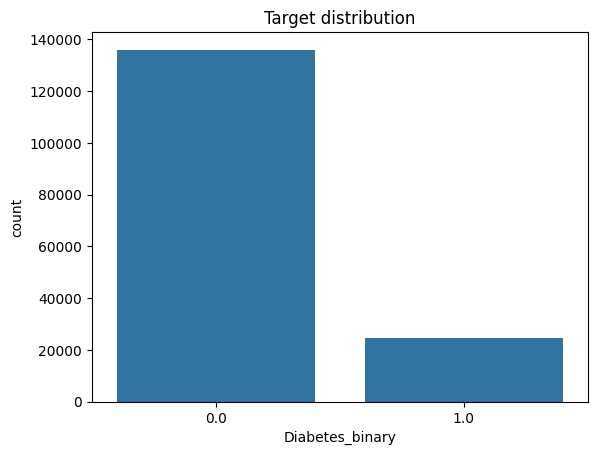

In [53]:
print(train["Diabetes_binary"].value_counts())
print(train["Diabetes_binary"].value_counts(normalize=True).round(3))

sns.countplot(x="Diabetes_binary", data=train)
plt.title("Target distribution")
plt.show()

## Gragh drawn shows that data is imbalanced, class0 : 85% while class1:15% 

In [54]:
numeric = ["BMI", "MentHlth", "PhysHlth"]
ordinal = ["GenHlth", "Age", "Education", "Income"]
binary = [c for c in train.columns if c not in numeric + ordinal + ["Diabetes_binary"]]

print("Binary :", len(binary), binary)
print("Ordinal:", len(ordinal), ordinal)
print("Numeric:", len(numeric), numeric)

Binary : 14 ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Ordinal: 4 ['GenHlth', 'Age', 'Education', 'Income']
Numeric: 3 ['BMI', 'MentHlth', 'PhysHlth']


### Target Distribution — Conclusion

- The training set contains 160,631 rows: about 85% non-diabetic (class 0) and 15% diabetic/prediabetic (class 1).
- The dataset is **imbalanced**, as shown by the bar chart and the class percentages.
- Accuracy alone would be misleading: a model that predicts "no diabetes" for everyone would reach ~85% accuracy while missing every diabetic case.
- Therefore, we will focus on **Recall, F1-score and PR-AUC**, and handle the imbalance in the preprocessing phase (using the training set only).

In [55]:
numeric = ["BMI", "MentHlth", "PhysHlth"]
train[numeric].describe().round(2)

,BMI,MentHlth,PhysHlth
count,160631.00,160631.00,160631.00
mean,28.67,3.52,4.67
std,6.77,7.73,9.04
min,12.00,0.00,0.00
25%,24.00,0.00,0.00
50%,27.00,0.00,0.00
75%,32.00,2.00,4.00
max,98.00,30.00,30.00


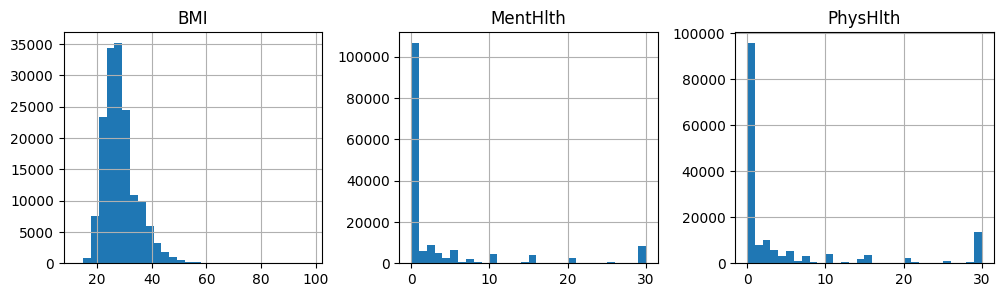

In [56]:
train[numeric].hist(bins=30, figsize=(12, 3), layout=(1, 3))
plt.show()

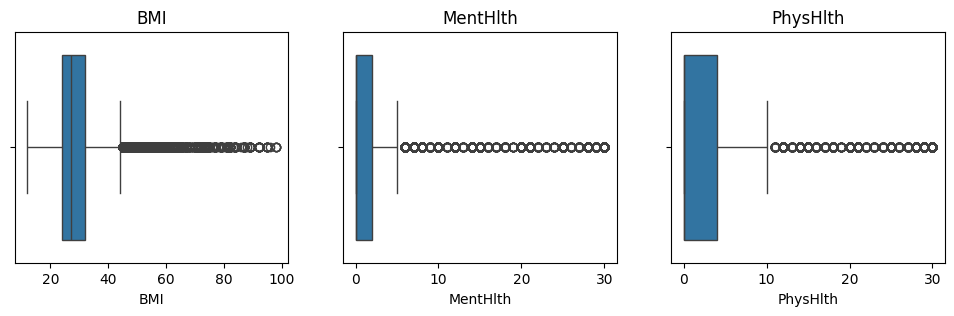

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, col in zip(axes, numeric):
    sns.boxplot(x=train[col], ax=ax)
    ax.set_title(col)
plt.show()

                   BMI  MentHlth  PhysHlth
Diabetes_binary                           
0.0              28.08      3.35      4.08
1.0              31.92      4.47      7.97

                  BMI  MentHlth  PhysHlth
Diabetes_binary                          
0.0              27.0       0.0       0.0
1.0              31.0       0.0       1.0


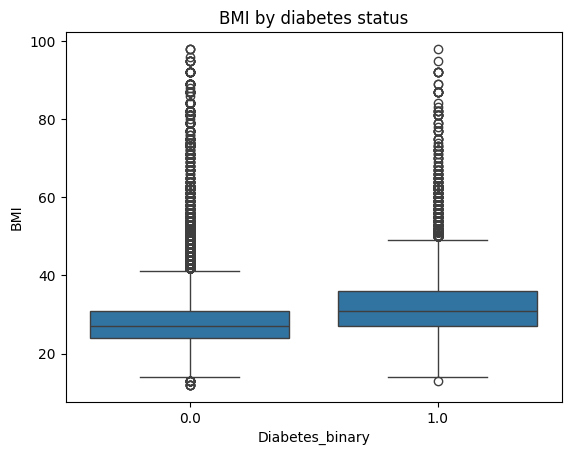

In [58]:
print(train.groupby("Diabetes_binary")[numeric].mean().round(2))
print()
print(train.groupby("Diabetes_binary")[numeric].median())

sns.boxplot(x="Diabetes_binary", y="BMI", data=train)
plt.title("BMI by diabetes status")
plt.show()

### Numeric Features — Conclusion

- **BMI** is right-skewed with a long upper tail (max = 98). The boxplot shows many points above ~44, but these are plausible survey values, so no change is made now. The decision on handling outliers is deferred to Preprocessing (using training data only).
- **MentHlth** and **PhysHlth** are heavily concentrated at 0 days (~66% and ~60%) with a second peak at 30 days. This U-shaped pattern is a natural feature of the question, not an error, so these values are not treated as outliers.
- People with diabetes have a higher average BMI (~31.9 vs ~28.1) and about twice as many physically unhealthy days (~8.0 vs ~4.1) than people without diabetes, so these features look useful for prediction.
- Proposed handling (to be applied in Preprocessing): cap BMI at training-set percentiles; keep all rows.

In [59]:
rows = []
for col in binary:
    rate = train.groupby(col)["Diabetes_binary"].mean()
    rows.append([col, rate.loc[0.0], rate.loc[1.0]])

bin_table = pd.DataFrame(rows, columns=["feature", "rate_if_0", "rate_if_1"]).set_index("feature")
bin_table["ratio"] = bin_table["rate_if_1"] / bin_table["rate_if_0"]
bin_table.round(3).sort_values("ratio", ascending=False)

,rate_if_0,rate_if_1,ratio
feature,,,
CholCheck,0.026,0.158,6.092
HighBP,0.070,0.254,3.648
DiffWalk,0.118,0.307,2.607
HighChol,0.091,0.232,2.561
HeartDiseaseorAttack,0.132,0.332,2.509
Stroke,0.145,0.317,2.180
AnyHealthcare,0.112,0.155,1.386
Smoker,0.137,0.171,1.244
Sex,0.143,0.166,1.163


- No feature is removed at the EDA stage. Weak candidates (Smoker, Sex, NoDocbcCost, AnyHealthcare, Fruits, Veggies) will be re-evaluated in Feature Selection using training data only, by comparing validation performance with and without them.

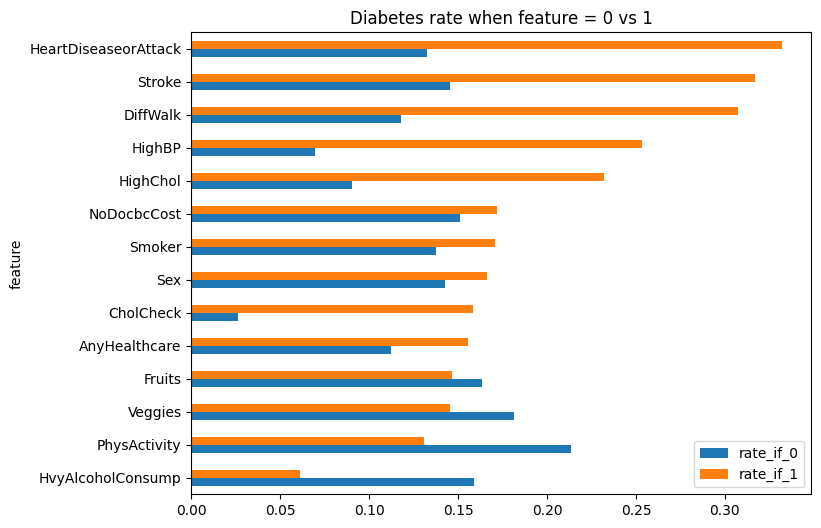

In [60]:
bin_table[["rate_if_0", "rate_if_1"]].sort_values("rate_if_1").plot.barh(figsize=(8, 6))
plt.title("Diabetes rate when feature = 0 vs 1")
plt.show()

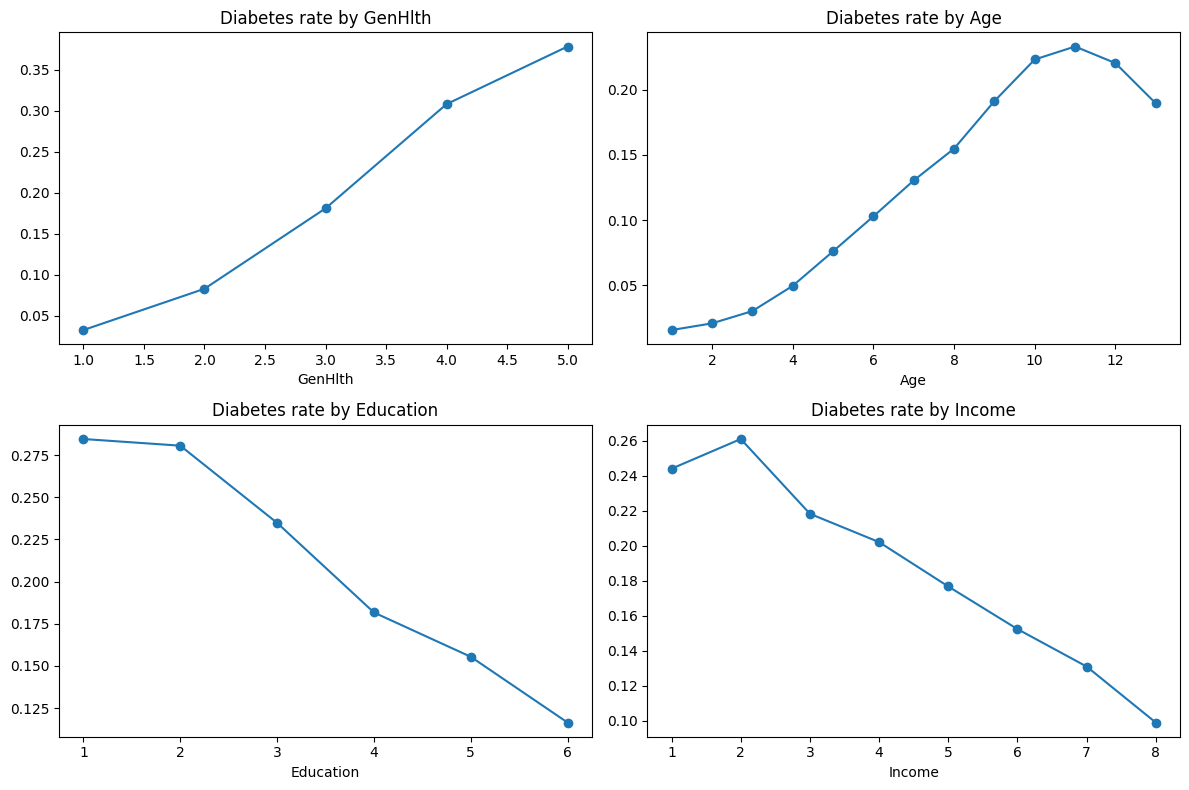

In [61]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ordinal):
    train.groupby(col)["Diabetes_binary"].mean().plot(marker="o", ax=ax)
    ax.set_title(f"Diabetes rate by {col}")
plt.tight_layout()
plt.show()

- **GenHlth:** The diabetes percentage increases consistently from 3.2% among individuals with excellent general health to 37.9% among those with poor general health.

- **Age:** The percentage increases from 1.6% in the youngest age group to approximately 23% in age group 11, then decreases slightly in the two oldest age groups.

- **Education:** The percentage decreases from 28.5% to 11.6% as the education level increases. However, category 1 contains only 123 rows, so its results should be interpreted with caution.

- **Income:** The percentage decreases from 24.4% to 9.9% as income level increases.

### Binary and Ordinal Features — Conclusion

- The strongest binary associations with diabetes are HighBP, DiffWalk, HighChol, HeartDiseaseorAttack and Stroke (diabetes rate 2–3.6x higher when present). PhysActivity is associated with a lower rate (13.1% vs 21.4%).
- Smoker, Sex, NoDocbcCost, AnyHealthcare, Fruits and Veggies show weak associations.
- GenHlth, Age, Education and Income show clear monotonic patterns: diabetes rate rises with worse general health and age (up to the 11th age group) and falls with higher education and income.
- Caution: CholCheck (6.1x) most likely reflects diagnosis/screening effects rather than risk, and HvyAlcoholConsump shows a counter-intuitive lower rate, possibly because people with diabetes are advised to avoid alcohol. These are associations, not causal effects.

GenHlth                 0.271034
HighBP                  0.254562
BMI                     0.216059
DiffWalk                0.204534
HighChol                0.194982
Age                     0.175859
HeartDiseaseorAttack    0.168824
PhysHlth                0.136705
Income                 -0.136260
PhysActivity           -0.101388
Stroke                  0.098444
Education              -0.095345
CholCheck               0.072461
HvyAlcoholConsump      -0.065077
Smoker                  0.046469
Veggies                -0.040363
Sex                     0.032091
AnyHealthcare           0.027145
Fruits                 -0.022806
MentHlth                0.017739
NoDocbcCost             0.017043
Name: Diabetes_binary, dtype: float64


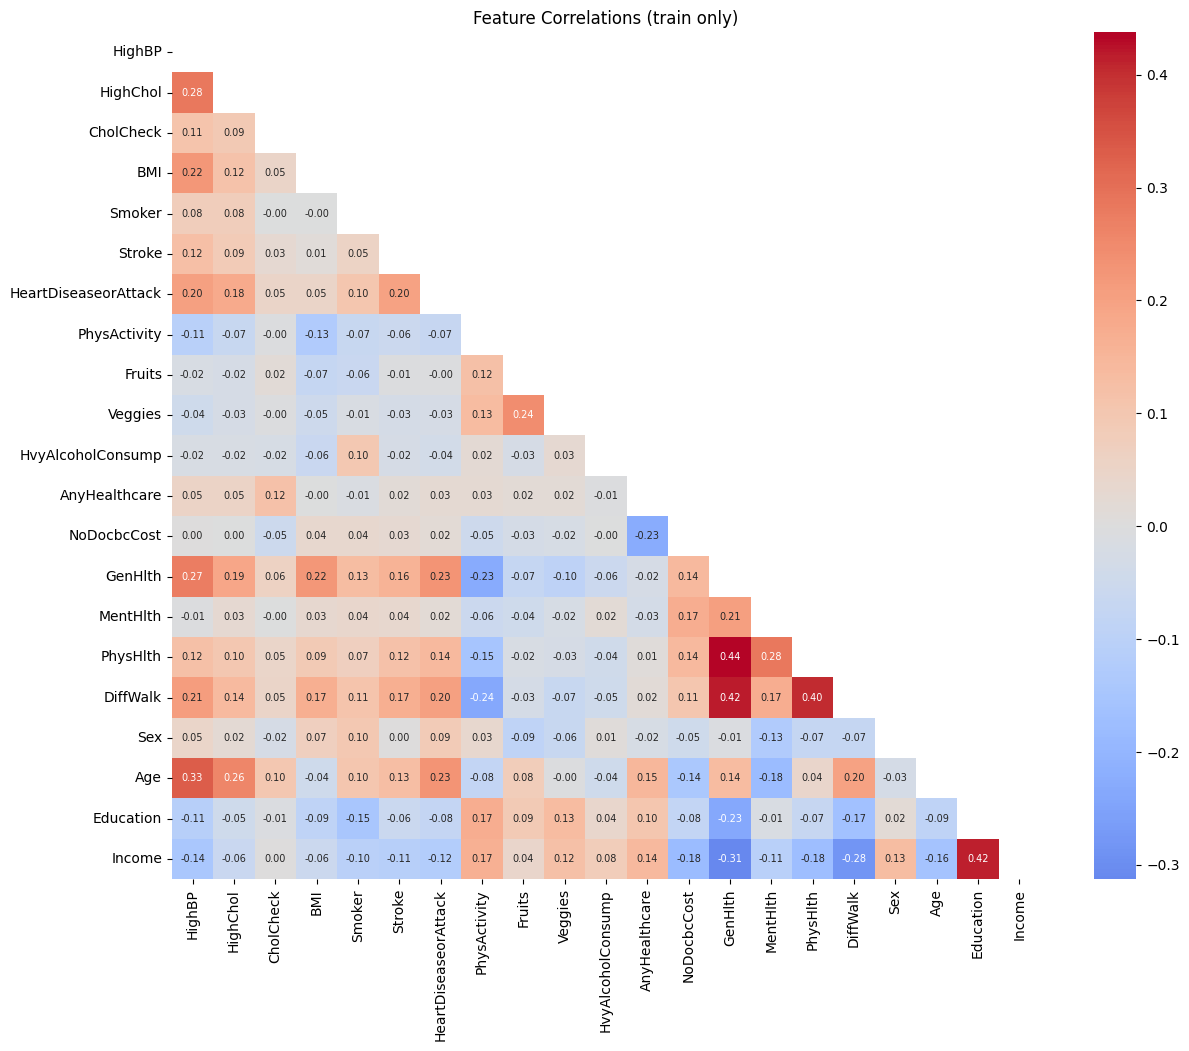

      level_0    level_1         r
118  PhysHlth    GenHlth  0.437796
133  DiffWalk    GenHlth  0.418475
209    Income  Education  0.416947
135  DiffWalk   PhysHlth  0.403550


In [62]:
train = train_df.copy()

# Feature vs Target
target_corr = (train.corr(method='spearman')['Diabetes_binary']
               .drop('Diabetes_binary').sort_values(key=abs, ascending=False))
print(target_corr)

#  Heatmap
corr = train.drop(columns='Diabetes_binary').corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(14, 11))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size':7})
plt.title('Feature Correlations (train only)')
plt.show()

# pair high correlated features
pairs = (corr.where(~mask).stack().rename('r').reset_index()
         .query('abs(r) > 0.4').sort_values('r', key=abs, ascending=False))
print(pairs)

## Correlation Analysis (train only, Spearman)

**Feature vs. target**
- Strongest positive: `GenHlth` (0.27), `HighBP` (0.25), `BMI` (0.22), `DiffWalk` (0.20), `HighChol` (0.19), `Age` (0.18), `HeartDiseaseorAttack` (0.17).
- Negative: `Income` (-0.14), `PhysActivity` (-0.10), `Education` (-0.10).
- Very weak (|r| < 0.05): `Smoker`, `Veggies`, `Sex`, `AnyHealthcare`, `Fruits`, `MentHlth`, `NoDocbcCost`.
- All correlations are modest, which is expected for a binary and imbalanced target.

**Feature vs. feature**
- Only 4 pairs have |r| > 0.4: PhysHlth–GenHlth (0.44), DiffWalk–GenHlth (0.42), Income–Education (0.42), DiffWalk–PhysHlth (0.40).
- None approaches 0.7, consistent with the VIF results (all < 1.8).

**Decision:** No features are removed based on correlation. Weakly correlated features are kept for now because Spearman only captures monotonic relationships and may miss non-linear effects or interactions that tree-based models can use. Final selection will be informed by Mutual Information and Random Forest importance in Phase 3.

> Correlation does not imply causation.

In [63]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_train_vif = train_df.drop(columns=TARGET).astype(float)
Xc = add_constant(X_train_vif)
vif = pd.DataFrame({
    'feature': Xc.columns,
    'VIF': [variance_inflation_factor(Xc.values, i) for i in range(Xc.shape[1])]
}).query("feature != 'const'").sort_values('VIF', ascending=False)
print(vif)

                 feature       VIF
14               GenHlth  1.713263
16              PhysHlth  1.588916
17              DiffWalk  1.508160
21                Income  1.428836
19                   Age  1.353530
1                 HighBP  1.300811
20             Education  1.273167
15              MentHlth  1.222311
7   HeartDiseaseorAttack  1.166816
2               HighChol  1.160070
13           NoDocbcCost  1.136804
8           PhysActivity  1.131009
4                    BMI  1.120943
12         AnyHealthcare  1.109865
10               Veggies  1.098590
9                 Fruits  1.098387
6                 Stroke  1.076720
5                 Smoker  1.076519
18                   Sex  1.076217
3              CholCheck  1.035009
11     HvyAlcoholConsump  1.026318


## Multicollinearity Check (VIF)

VIF was computed on the **training set only** to avoid data leakage.

- Highest: `GenHlth` (1.71), then `PhysHlth` (1.59) and `DiffWalk` (1.51)
- All other features: below 1.5

**Decision:** All values are well below the threshold of 5, so multicollinearity is negligible. No features will be removed or combined, and Logistic Regression coefficients can be interpreted without stability concerns.

> VIF only measures redundancy between features, not their relevance to the target. Relevance is assessed separately via target correlation.

In [64]:
for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(name, '| missing:', d.isna().sum().sum(), '| duplicates:', d.duplicated().sum())


key = list(train_df.columns)
overlap = pd.merge(train_df.drop_duplicates(), test_df.drop_duplicates(), on=key).shape[0]
print('train/test overlapping rows:', overlap)


print(train_df[['BMI','MentHlth','PhysHlth','GenHlth','Age','Education','Income']].describe().T[['min','max']])

train | missing: 0 | duplicates: 0
val | missing: 0 | duplicates: 0
test | missing: 0 | duplicates: 0
train/test overlapping rows: 0
            min   max
BMI        12.0  98.0
MentHlth    0.0  30.0
PhysHlth    0.0  30.0
GenHlth     1.0   5.0
Age         1.0  13.0
Education   1.0   6.0
Income      1.0   8.0


In [65]:
X_train, y_train = train_df.drop(columns=TARGET), train_df[TARGET]
X_val,   y_val   = val_df.drop(columns=TARGET),   val_df[TARGET]
X_test,  y_test  = test_df.drop(columns=TARGET),  test_df[TARGET]

In [66]:
from sklearn.base import BaseEstimator, TransformerMixin

class QuantileClipper(BaseEstimator, TransformerMixin):
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_  = np.quantile(X, self.lower, axis=0)
        self.high_ = np.quantile(X, self.upper, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)

In [67]:
continuous = ['BMI']
scaled_only = ['MentHlth', 'PhysHlth', 'GenHlth', 'Age', 'Education', 'Income']
binary = [c for c in X_train.columns if c not in continuous + scaled_only]

In [68]:
prep_linear = ColumnTransformer([
    ('bmi',  Pipeline([('clip', QuantileClipper()), ('scale', StandardScaler())]), continuous),
    ('num',  StandardScaler(), scaled_only),
    ('bin',  'passthrough', binary),
])
prep_tree = 'passthrough'

In [69]:
pipe_lr = Pipeline([
    ('prep', prep_linear),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED)),
])

pipe_dt = Pipeline([
    ('prep', prep_tree),
    ('clf', DecisionTreeClassifier(class_weight='balanced', max_depth=8,
                                   min_samples_leaf=50, random_state=SEED)),
])

pipe_rf = Pipeline([
    ('prep', prep_tree),
    ('clf', RandomForestClassifier(class_weight='balanced_subsample', n_estimators=300,
                                   min_samples_leaf=20, n_jobs=-1, random_state=SEED)),
])

## Phase 3: Preprocessing Decisions

- **Missing values / duplicates:** none found (duplicates removed before the split).
- **Split:** 70/15/15 stratified; validation is used for tuning, test only for final evaluation.
- **Outliers:** BMI clipped to the 1st-99th percentile (learned from train only, inside the Pipeline). No rows removed.
- **Scaling:** StandardScaler for the Logistic Regression only. Tree models use raw features.
- **Encoding:** none needed. All features are binary or ordinal numeric.
- **Class imbalance (~14% positive):** handled with `class_weight` inside each model, not by resampling.
- **Leakage prevention:** every fitted step (clipper, scaler) lives inside the Pipeline and learns from training data only.

In [70]:
pipe_lr.fit(X_train, y_train)
print('LR val accuracy:', pipe_lr.score(X_val, y_val))

LR val accuracy: 0.7187472763719822


In [71]:
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

y_pred = pipe_lr.predict(X_val)
y_prob = pipe_lr.predict_proba(X_val)[:, 1]

print(classification_report(y_val, y_pred, digits=3))
print('ROC-AUC:', round(roc_auc_score(y_val, y_prob), 4))
print(confusion_matrix(y_val, y_pred))

              precision    recall  f1-score   support

         0.0      0.944     0.710     0.811     29157
         1.0      0.323     0.767     0.455      5264

    accuracy                          0.719     34421
   macro avg      0.634     0.738     0.633     34421
weighted avg      0.849     0.719     0.756     34421

ROC-AUC: 0.8141
[[20705  8452]
 [ 1229  4035]]


## Baseline: Logistic Regression (validation set)

| Metric (class 1) | Value |
|---|---|
| Recall | 0.767 |
| Precision | 0.323 |
| F1 | 0.455 |
| ROC-AUC | 0.814 |

Confusion matrix: TN=20705, FP=8452, FN=1229, TP=4035.

The model prioritizes recall (via `class_weight='balanced'`), accepting many false positives to miss fewer true diabetes cases. Accuracy (0.719) is not used for model selection because of the class imbalance.

In [72]:
def evaluate(name, pipe, X, y):
    pipe.fit(X_train, y_train) if not hasattr(pipe, 'classes_') else None
    y_pred = pipe.predict(X)
    y_prob = pipe.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    return {
        'model': name,
        'accuracy': accuracy_score(y, y_pred),
        'precision': precision_score(y, y_pred),
        'recall': recall_score(y, y_pred),
        'f1': f1_score(y, y_pred),
        'roc_auc': roc_auc_score(y, y_prob),
        'FN': fn, 'FP': fp,
    }

In [73]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

def evaluate(name, pipe, X, y):
    y_pred = pipe.predict(X)
    y_prob = pipe.predict_proba(X)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y, y_pred).ravel()
    return {'model': name,
            'accuracy': accuracy_score(y, y_pred),
            'precision': precision_score(y, y_pred),
            'recall': recall_score(y, y_pred),
            'f1': f1_score(y, y_pred),
            'roc_auc': roc_auc_score(y, y_prob),
            'FN': fn, 'FP': fp}

models = {'Logistic Regression': pipe_lr,
          'Decision Tree': pipe_dt,
          'Random Forest': pipe_rf}

results = []
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    results.append(evaluate(name, pipe, X_val, y_val))

results_df = pd.DataFrame(results).set_index('model').round(3)
print(results_df)

                     accuracy  precision  recall     f1  roc_auc    FN    FP
model                                                                       
Logistic Regression     0.719      0.323   0.767  0.455    0.814  1229  8452
Decision Tree           0.694      0.305   0.782  0.439    0.805  1146  9374
Random Forest           0.738      0.338   0.746  0.465    0.818  1337  7694


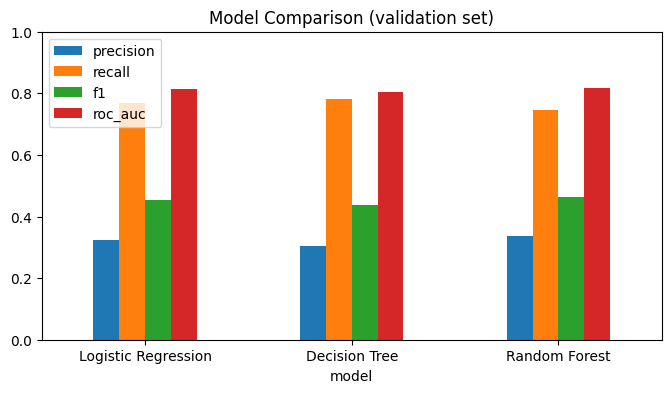

In [74]:
results_df[['precision', 'recall', 'f1', 'roc_auc']].plot(kind='bar', figsize=(8, 4), ylim=(0, 1))
plt.title('Model Comparison (validation set)')
plt.xticks(rotation=0)
plt.show()

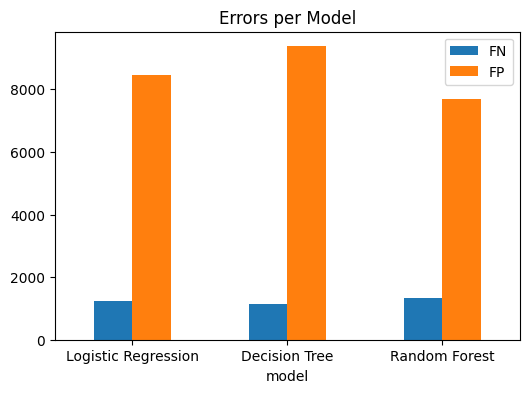

In [75]:
results_df[['FN', 'FP']].plot(kind='bar', figsize=(6, 4))
plt.title('Errors per Model')
plt.xticks(rotation=0)
plt.show()

In [77]:
from sklearn.model_selection import GridSearchCV

grids = {
    'Logistic Regression': (pipe_lr, {'clf__C': [0.1, 1, 10]}),
    'Decision Tree':       (pipe_dt, {'clf__max_depth': [4, 6, 8, 12]}),
    'Random Forest':       (pipe_rf, {'clf__max_depth': [10, 15]}),
}

best_models = {}
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, scoring='roc_auc', cv=3)
    gs.fit(X_train, y_train)
    best_models[name] = gs.best_estimator_
    print(name, gs.best_params_, round(gs.best_score_, 4))

Logistic Regression {'clf__C': 0.1} 0.8078
Decision Tree {'clf__max_depth': 8} 0.7991
Random Forest {'clf__max_depth': 15} 0.812


In [78]:
rows = [evaluate(name, m, X_val, y_val) for name, m in best_models.items()]
tuned_df = pd.DataFrame(rows).set_index('model').round(3)
print(tuned_df)

                     accuracy  precision  recall     f1  roc_auc    FN    FP
model                                                                       
Logistic Regression     0.719      0.323   0.767  0.455    0.814  1229  8446
Decision Tree           0.694      0.305   0.782  0.439    0.805  1146  9374
Random Forest           0.733      0.335   0.756  0.464    0.818  1287  7911


In [79]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

model = best_models['Random Forest']
prob = model.predict_proba(X_val)[:, 1]

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (prob >= t).astype(int)
    print(t,
          'acc', round(accuracy_score(y_val, pred), 3),
          'prec', round(precision_score(y_val, pred), 3),
          'recall', round(recall_score(y_val, pred), 3))

0.3 acc 0.559 prec 0.248 recall 0.925
0.4 acc 0.652 prec 0.287 recall 0.858
0.5 acc 0.733 prec 0.335 recall 0.756
0.6 acc 0.792 prec 0.387 recall 0.611
0.7 acc 0.836 prec 0.46 recall 0.414


In [80]:
for t in [0.50, 0.52, 0.54, 0.56, 0.58]:
    pred = (prob >= t).astype(int)
    print(t,
          'acc', round(accuracy_score(y_val, pred), 3),
          'prec', round(precision_score(y_val, pred), 3),
          'recall', round(recall_score(y_val, pred), 3))

0.5 acc 0.733 prec 0.335 recall 0.756
0.52 acc 0.747 prec 0.345 recall 0.728
0.54 acc 0.76 prec 0.355 recall 0.698
0.56 acc 0.771 prec 0.364 recall 0.666
0.58 acc 0.782 prec 0.375 recall 0.639


In [81]:
import numpy as np

rows = []
for name, model in best_models.items():
    prob = model.predict_proba(X_val)[:, 1]
    best_t, best_acc = 0.5, 0
    for t in np.arange(0.3, 0.8, 0.01):
        pred = (prob >= t).astype(int)
        if recall_score(y_val, pred) >= 0.70 and accuracy_score(y_val, pred) > best_acc:
            best_t, best_acc = t, accuracy_score(y_val, pred)
    pred = (prob >= best_t).astype(int)
    rows.append({'model': name, 'threshold': round(best_t, 2),
                 'accuracy': accuracy_score(y_val, pred),
                 'precision': precision_score(y_val, pred),
                 'recall': recall_score(y_val, pred)})

final_df = pd.DataFrame(rows).set_index('model').round(3)
print(final_df)

                     threshold  accuracy  precision  recall
model                                                      
Logistic Regression       0.55     0.749      0.345   0.709
Decision Tree             0.57     0.735      0.332   0.725
Random Forest             0.53     0.754      0.351   0.714


In [82]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

model = best_models['Random Forest']
prob = model.predict_proba(X_test)[:, 1]
pred = (prob >= 0.53).astype(int)

print(classification_report(y_test, pred, digits=3))
print('ROC-AUC:', round(roc_auc_score(y_test, prob), 4))
print(confusion_matrix(y_test, pred))

              precision    recall  f1-score   support

         0.0      0.935     0.756     0.836     29157
         1.0      0.344     0.708     0.463      5265

    accuracy                          0.749     34422
   macro avg      0.639     0.732     0.650     34422
weighted avg      0.844     0.749     0.779     34422

ROC-AUC: 0.8154
[[22047  7110]
 [ 1536  3729]]


HighBP                  0.199
GenHlth                 0.197
BMI                     0.145
Age                     0.118
HighChol                0.088
DiffWalk                0.043
PhysHlth                0.035
Income                  0.034
HeartDiseaseorAttack    0.027
MentHlth                0.021
Education               0.017
Sex                     0.014
HvyAlcoholConsump       0.011
PhysActivity            0.011
CholCheck               0.010
Smoker                  0.009
Fruits                  0.008
Veggies                 0.005
Stroke                  0.004
NoDocbcCost             0.003
AnyHealthcare           0.002
dtype: float64


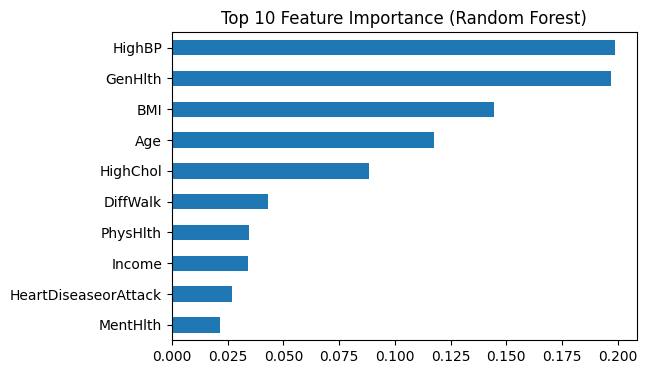

In [83]:
rf = model.named_steps['clf']

importance = pd.Series(rf.feature_importances_, index=X_train.columns)
importance = importance.sort_values(ascending=False)
print(importance.round(3))

importance.head(10).plot(kind='barh', figsize=(6, 4))
plt.gca().invert_yaxis()
plt.title('Top 10 Feature Importance (Random Forest)')
plt.show()

In [84]:
target_corr = train_df.corr(method='spearman')[TARGET].drop(TARGET).abs()
compare = pd.DataFrame({'RF importance': importance, 'abs corr': target_corr}).round(3)
print(compare.sort_values('RF importance', ascending=False))

                      RF importance  abs corr
HighBP                        0.199     0.255
GenHlth                       0.197     0.271
BMI                           0.145     0.216
Age                           0.118     0.176
HighChol                      0.088     0.195
DiffWalk                      0.043     0.205
PhysHlth                      0.035     0.137
Income                        0.034     0.136
HeartDiseaseorAttack          0.027     0.169
MentHlth                      0.021     0.018
Education                     0.017     0.095
Sex                           0.014     0.032
HvyAlcoholConsump             0.011     0.065
PhysActivity                  0.011     0.101
CholCheck                     0.010     0.072
Smoker                        0.009     0.046
Fruits                        0.008     0.023
Veggies                       0.005     0.040
Stroke                        0.004     0.098
NoDocbcCost                   0.003     0.017
AnyHealthcare                 0.00

## Feature Importance (Random Forest)

- The top 5 features (`HighBP` 0.199, `GenHlth` 0.197, `BMI` 0.145, `Age` 0.118, `HighChol` 0.088) account for about 75% of total importance.
- This agrees with the EDA correlations on the strongest features and on the weakest ones (`AnyHealthcare`, `NoDocbcCost`, `Veggies`, `Fruits`).
- Some features (`DiffWalk`, `HeartDiseaseorAttack`, `Stroke`) have a notable correlation but low importance, because their information overlaps with stronger features such as `GenHlth`, `HighBP` and `Age`.
- Impurity-based importance can favor features with many distinct values (such as `BMI`).

> These are associations, not causes. Some features (e.g. `GenHlth`, `DiffWalk`) may be consequences of diabetes rather than risk factors.

In [85]:
from sklearn.inspection import permutation_importance

r = permutation_importance(model, X_val, y_val, scoring='roc_auc', n_repeats=3, random_state=SEED)
print(pd.Series(r.importances_mean, index=X_val.columns).sort_values(ascending=False).round(3))

GenHlth                 0.044
BMI                     0.034
Age                     0.029
HighBP                  0.023
HighChol                0.012
HvyAlcoholConsump       0.003
HeartDiseaseorAttack    0.003
CholCheck               0.003
Sex                     0.002
Income                  0.002
DiffWalk                0.002
MentHlth                0.001
Education               0.000
PhysHlth                0.000
Stroke                  0.000
Smoker                  0.000
Veggies                 0.000
AnyHealthcare           0.000
PhysActivity            0.000
NoDocbcCost             0.000
Fruits                 -0.000
dtype: float64


- Near-zero importance does not mean no association with diabetes, only that the model gains little from the feature given the others.

In [86]:
import joblib
joblib.dump({'model': model, 'threshold': 0.53, 'columns': list(X_train.columns)}, 'diabetes_model.joblib')

['diabetes_model.joblib']

In [87]:
import joblib

saved = joblib.load('diabetes_model.joblib')
model = saved['model']
threshold = saved['threshold']
columns = saved['columns']

person = X_val.iloc[[0]]
prob = model.predict_proba(person[columns])[0, 1]

print('probability:', round(prob, 3))
print('prediction:', 'Diabetes' if prob >= threshold else 'No diabetes')

probability: 0.328
prediction: No diabetes


In [88]:
import os
print(os.getcwd())


c:\Users\macht\Desktop\diabetes risk analysis
